```{index} single: solver; HiGHS
```
# 3.6 Facility location problem

This notebook illustrates Example 3.10 from Chapter 3 of the textbook Hands-On Mathematical Optimization with Python, Cambridge University Press, 2025.

For details about these models and more information we refer to the book.

Also notice that at the end of Chapter 3 you may find a number of exercises that show that versions of this problem aiming at maximizing the importance of the customers served, when facing constraints that limit the possibility of serving all, lead to even more striking evidence for the importance of selecting the right model: it can offer large factors of speedup in solving the relevant instances!


## Preamble: Install Pyomo and a solver

This notebook runs with Pyomo and the open-source HiGHS solver. The following cell installs them on Colab; install `pyomo highspy` locally before running elsewhere. Comparisons with other solvers are optional and require their installations and, for commercial solvers, suitable licenses. Each solve below has a ten-second limit; the reports distinguish optimal solutions, feasible incumbents and runs without an incumbent.

See [Solvers used in this book](../appendix/installing-pyomo-and-solvers.ipynb) for installation, licensing and the differences between solver interfaces.

In [1]:
import sys

if 'google.colab' in sys.modules:
    %pip install -q pyomo highspy

import pyomo.environ as pyo
assert pyo.SolverFactory("appsi_highs").available(), "Install highspy to run this notebook."
CANDIDATE_SOLVERS = ["appsi_highs"]
MAX_SOLVE_SECONDS = 10

## Problem description

Consider the problem of a supplier facing the task of fulfilling specific customer demands with minimal costs while simultaneously deciding how many facilities to build and where. In terms of data, we are given a set $I$ of customers, a set $J$ of possible locations, the cost $c_j$ of building facility $j$, and the cost $h_{ij}$ incurred to satisfy the demands of customer $i$ at facility $j$.

In this notebook we will formulate two equivalent models for this problem and compare their performance.

## First MILO formulation

Introduce two sets of binary variables,

$$
\begin{equation*}
    x_j:=
    \begin{cases}
    1 & \text{ if facility $j$ is built,}\\
    0 & \text{ otherwise,}
    \end{cases}
\end{equation*}
$$

and

$$
\begin{equation*}
    y_{ij}:=
    \begin{cases}
    1 & \text{ if customer $i$ is served at facility $j$,}\\
    0 & \text{ otherwise.}
    \end{cases}
\end{equation*}
$$

The resulting MILO is

$$
\begin{align*}
    \min \quad & \sum_{j \in J} c_j x_j + \sum_{i \in I} \sum_{j \in J} h_{ij} y_{ij} \\
    \text{s.t.} \quad & \sum_{j \in J} y_{ij} =1 \qquad \forall \, i \in I & \text{(every customer is served)}\\
    & y_{ij} \leq x_{j} \qquad \forall \, i\in I, \, \forall \, j \in J & \text{(facility built before use)}\\
    & x_j \in \{0,1\} \qquad \forall \, j\in J\\
    & y_{ij} \in \{0,1\} \qquad \forall \, i\in I, \, \forall \, j \in J.
\end{align*}
$$

## Second MILO formulation

Let $n=|J|$ be the number of possible facility locations and $m=|I|$ the number of customers. Note that, since $\sum_j y_{ij} =1$ for every $i \in I$, we can replace the $n \times m$ constraints $y_{ij} \leq x_j$ by only $n$ constraints, namely

$$
\begin{equation*}
    \sum_{i \in I} y_{ij} \leq m x_j \qquad \forall \, j \in J.
\end{equation*}
$$

The second MILO is

$$
\begin{align*}
    \min \quad & \sum_{j \in J} c_j x_j + \sum_{i \in I} \sum_{j \in J} h_{ij} y_{ij} \\
    \text{s.t.} \quad & \sum_{j \in J} y_{ij} =1 \qquad \forall \, i \in I & \text{(every customer is served)}\\
    & \sum_{i \in I} y_{ij} \leq m x_j \qquad \forall \, j \in J & \text{(facility built before use)}\\
    & x_j \in \{0,1\} \qquad \forall \, j\in J\\
    & y_{ij} \in \{0,1\} \qquad \forall \, i\in I, \, \forall \, j \in J.
\end{align*}
$$

This approach leads to a more concise mathematical formulation of the model. However, it may not be a good idea if we want to solve the problem using its linear relaxation. Indeed, by reducing the number of constraints, we inadvertently made the feasible region of the relaxation larger and less tight around the feasible integer points. This fact becomes clearly evident in the increased run-time required to solve the optimization problem when working with these weaker constraints, see figures below.

Instead of defining two separate Pyomo models, we will define a single common model and then add either the strong or weaker formulation of the "facility built before use" constraint.

In [2]:
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import itertools as it
import matplotlib.pyplot as plt
from time import perf_counter as pc
from tqdm.auto import tqdm

## Solvers and options

In [3]:
def MakeSolver(name):
    solver = pyo.SolverFactory(name)
    solver._book_name = name
    return solver


def ListAvailableSolvers(names=None):
    names = CANDIDATE_SOLVERS if names is None else names
    return [name for name in names
            if pyo.SolverFactory(name).available(exception_flag=False)]


def GetSolverName(solver):
    return solver._book_name


def SwitchCutsOff(solver):
    solver_name = GetSolverName(solver)
    if "cbc" in solver_name:
        solver.options["Cuts"] = "off"
    elif "cplex" in solver_name:
        solver.options["mip_cuts_bqp"] = -1
        solver.options["mip_cuts_cliques"] = -1
        solver.options["mip_cuts_covers"] = -1
        solver.options["mip_cuts_disjunctive"] = -1
        solver.options["mip_cuts_flowcovers"] = -1
        solver.options["mip_cuts_pathcut"] = -1
        solver.options["mip_cuts_gomory"] = -1
        solver.options["mip_cuts_gubcovers"] = -1
        solver.options["mip_cuts_implied"] = -1
        solver.options["mip_cuts_localimplied"] = -1
        solver.options["mip_cuts_liftproj"] = -1
        solver.options["mip_cuts_mircut"] = -1
        solver.options["mip_cuts_mcfcut"] = -1
        solver.options["mip_cuts_rlt"] = -1
        solver.options["mip_cuts_zerohalfcut"] = -1
    elif "gurobi" in solver_name:
        solver.options["Cuts"] = 0
    elif "highs" in solver_name:
        raise ValueError("This notebook does not disable HiGHS cuts.")
    elif "xpress" in solver_name:
        solver.options["CUTSTRATEGY"] = 0
    else:
        pass
    return solver


def SwitchPresolveOff(solver):
    solver_name = GetSolverName(solver)
    if "cbc" in solver_name:
        solver.options["Presolve"] = "off"
    elif "cplex" in solver_name:
        solver.options["preprocessing_presolve"] = 0
    elif "gurobi" in solver_name:
        solver.options["Presolve"] = 0
    elif "highs" in solver_name:
        solver.options["presolve"] = "off"
    elif "xpress" in solver_name:
        solver.options["PRESOLVE"] = 0
    else:
        pass
    return solver


def LimitSolveTime(solver, max_in_seconds):
    solver_name = GetSolverName(solver)
    if "cbc" in solver_name:
        solver.options["seconds"] = max_in_seconds
    elif "cplex" in solver_name:
        solver.options["timelimit"] = max_in_seconds
    elif "gurobi" in solver_name:
        solver.options["TimeLimit"] = max_in_seconds
    elif "highs" in solver_name:
        solver.options["time_limit"] = max_in_seconds
    elif "xpress" in solver_name:
        solver.options["TIMELIMIT"] = max_in_seconds
    else:
        pass
    return solver


def ClosureForMaxTime(max_in_seconds):
    return lambda solver: LimitSolveTime(solver, max_in_seconds)

In [4]:
def compose(*functions):
    def composed(*args, **kwargs):
        result = args[0]
        for func in functions:
            result = func(result)
        return result

    return composed

In [5]:
initial_solvers = ListAvailableSolvers()
initial_solvers

['appsi_highs']

## The models

In [6]:
def FacilityLocationCommon(installation, service):
    model = pyo.ConcreteModel("Facility location")
    model.facilities = pyo.Set(initialize=range(len(installation)))
    model.customers = pyo.Set(initialize=range(len(service)))

    model.x = pyo.Var(model.facilities, within=pyo.Binary)
    model.y = pyo.Var(model.customers, model.facilities, within=pyo.Binary)

    @model.Objective(sense=pyo.minimize)
    def obj(model):
        return sum(installation[j] * model.x[j] for j in model.facilities) + sum(
            service[i][j] * model.y[i, j]
            for i in model.customers
            for j in model.facilities
        )

    @model.Constraint(model.customers)
    def ChooseOneFacility(model, i):
        return sum(model.y[i, j] for j in model.facilities) == 1

    return model


def FacilityLocationWeak(installation, service):
    model = FacilityLocationCommon(installation, service)
    model.name += " weak model"

    @model.Constraint(model.facilities)
    def ServeIfOpen(model, j):
        return (
            sum(model.y[i, j] for i in model.customers)
            <= len(model.customers) * model.x[j]
        )

    return model


def FacilityLocationStrong(installation, service):
    model = FacilityLocationCommon(installation, service)
    model.name += " strong model"

    @model.Constraint(model.customers, model.facilities)
    def ServeIfOpen(model, i, j):
        return model.y[i, j] <= model.x[j]

    return model


def GetSolution(model):
    X = [model.x[j]() > 0.5 for j in model.facilities]
    Y = [[model.y[i, j]() > 0.5 for j in model.facilities] for i in model.customers]
    return X, Y, model.obj()

We introduce functions to generate random instances for the problem and to then visualize the optimal solution.

In [7]:
def GenerateFacilityLocationInstance(nofFacilities, nofCustumers):
    facilities = range(nofFacilities)
    customers = range(nofCustumers)
    xC = np.random.randint(0, 100, nofCustumers)
    yC = np.random.randint(0, 100, nofCustumers)
    xF = np.random.randint(0, 100, nofFacilities)
    yF = np.random.randint(0, 100, nofFacilities)

    installation = np.random.randint(1000, 2000, nofFacilities)

    dist = lambda i, j: ((xC[i] - xF[j]) ** 2 + (yC[i] - yF[j]) ** 2)

    service = [[dist(i, j) for j in facilities] for i in customers]

    return installation, service, xC, yC, xF, yF


def ShowFacilityLocation(xC, yC, xF, yF, X=[], Y=[], value=None, title=None, ax=None):
    if ax is None:
        ax = plt.gca()
    [
        ax.plot([xC[i], xF[j]], [yC[i], yF[j]], "g-")
        for j in range(len(X))
        if X[j]
        for i in range(len(Y))
        if Y[i][j]
    ]
    ax.plot(xC, yC, "o")
    ax.plot(xF, yF, "s")
    if title:
        ax.set_title(title)
    elif value:
        ax.set_title(f"Optimal value: {value}")

We then generate an instance of the problem with 20 facilities and 200 customers and initialize both a strong and a weak Pyomo model.

A time limit may leave a feasible solution without proving optimality. When Pyomo loads such a solution, it can warn that the solver status is "aborted". This refers to the stopping condition, not an error in the solution. The following functions check the returned variable values, bounds, integrality and constraints before reporting an incumbent; the reports retain its termination condition and optimality gap.

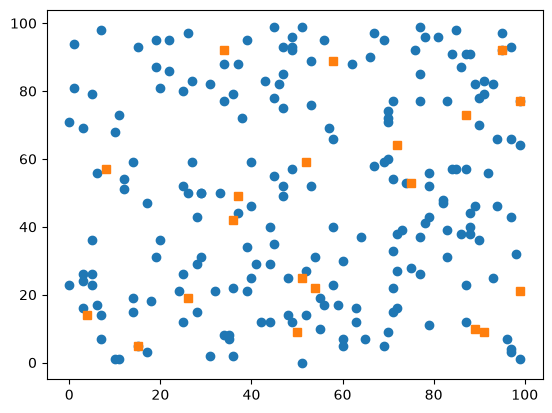

In [8]:
np.random.seed(2023)

installation, service, xC, yC, xF, yF = GenerateFacilityLocationInstance(20, 200)
ShowFacilityLocation(xC, yC, xF, yF)

weak = FacilityLocationWeak(installation, service)
strong = FacilityLocationStrong(installation, service)

In [9]:
def FiniteValue(value):
    try:
        value = float(value)
        return value if np.isfinite(value) else float("nan")
    except (TypeError, ValueError):
        return float("nan")


def LoadIncumbent(model, results, tolerance=1e-5):
    variables = list(model.component_data_objects(pyo.Var))
    # Previously loaded values are not evidence of a new solution.
    for v in variables:
        if not v.fixed:
            v.set_value(None)
    if not len(results.solution) or not results.solution[0].variable:
        return False
    model.solutions.load_from(results)
    complete = all(np.isfinite(FiniteValue(v.value)) for v in variables)
    feasible = complete and all(
        (v.lb is None or v.value >= pyo.value(v.lb) - tolerance)
        and (v.ub is None or v.value <= pyo.value(v.ub) + tolerance)
        and (not v.is_integer() or abs(v.value - round(v.value)) <= tolerance)
        for v in variables
    )
    if feasible:
        feasible = all(
            np.isfinite(FiniteValue(pyo.value(c.body)))
            and (c.lower is None or pyo.value(c.body) >= pyo.value(c.lower) - tolerance)
            and (c.upper is None or pyo.value(c.body) <= pyo.value(c.upper) + tolerance)
            for c in model.component_data_objects(pyo.Constraint, active=True)
        ) and np.isfinite(FiniteValue(pyo.value(model.obj)))
    if not feasible:
        for v in variables:
            if not v.fixed:
                v.set_value(None)
    return bool(feasible)


def SolveRecord(solver, model):
    LimitSolveTime(solver, MAX_SOLVE_SECONDS)
    started = pc()
    results = solver.solve(model, load_solutions=False)
    elapsed = pc() - started
    has_solution = LoadIncumbent(model, results)
    optimal = has_solution and pyo.check_optimal_termination(results)
    lower = FiniteValue(results.problem.lower_bound)
    value = model.obj() if has_solution else float("nan")
    gap = (max(0.0, value - lower) / max(abs(value), 1e-10)
           if has_solution and np.isfinite(lower) else float("nan"))
    return {"solver": GetSolverName(solver), "seconds": elapsed,
            "termination": str(results.solver.termination_condition),
            "optimal": optimal, "has_solution": has_solution,
            "incumbent": value, "lower_bound": lower, "relative_gap": gap}


def Solve(solver, model):
    record = SolveRecord(solver, model)
    if record["has_solution"]:
        X, Y, value = GetSolution(model)
        quality = "optimal" if record["optimal"] else f"incumbent, gap {record['relative_gap']:.1%}"
        detail = f"{quality}: {value:.0f}"
    else:
        X, Y, value = [], [], None
        detail = "no usable incumbent"
    title = (f"{model.name} | {record['solver']}\n"
             f"{record['seconds']:.2f} s | {detail} ({record['termination']})")
    return X, Y, value, title

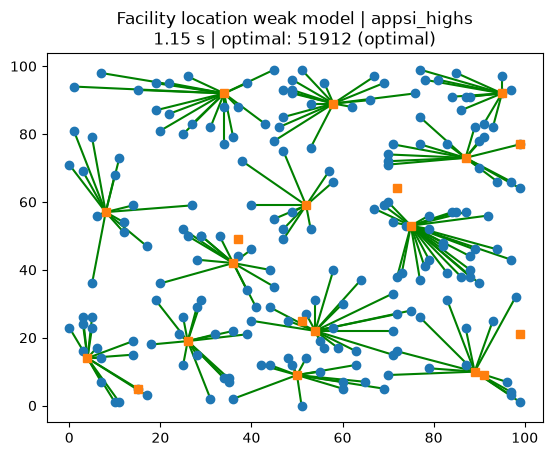

In [10]:
solver = MakeSolver("appsi_highs")
ShowFacilityLocation(xC, yC, xF, yF, *Solve(solver, weak))

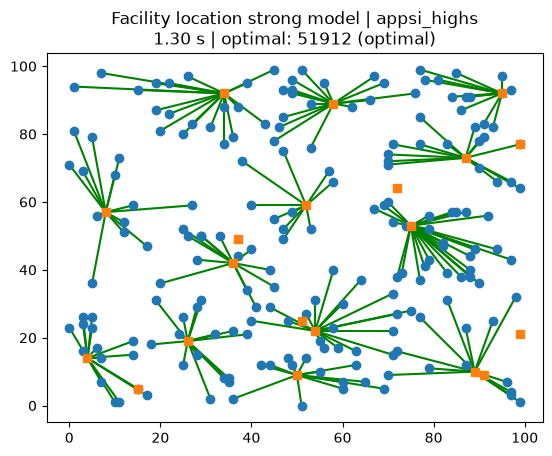

In [11]:
ShowFacilityLocation(xC, yC, xF, yF, *Solve(solver, strong))

Solvers use presolve and cuts, so a tighter formulation does not necessarily solve faster on every instance. The following optional installation cell enables comparisons with commercial solvers. Leave the flag `False` to use only HiGHS; set it to `True` only after arranging the relevant licenses. Availability checks detect installed interfaces, not whether a license covers a particular model.

In [12]:
USE_COMMERCIAL_SOLVERS = False
CANDIDATE_SOLVERS = ["appsi_highs"]
if USE_COMMERCIAL_SOLVERS:
    if 'google.colab' in sys.modules:
        %pip install -q gurobipy cplex xpress
    CANDIDATE_SOLVERS.extend(["gurobi_direct", "cplex_direct", "xpress_direct"])

In [13]:
available_solvers = ListAvailableSolvers()
set(available_solvers) - set(initial_solvers)

set()

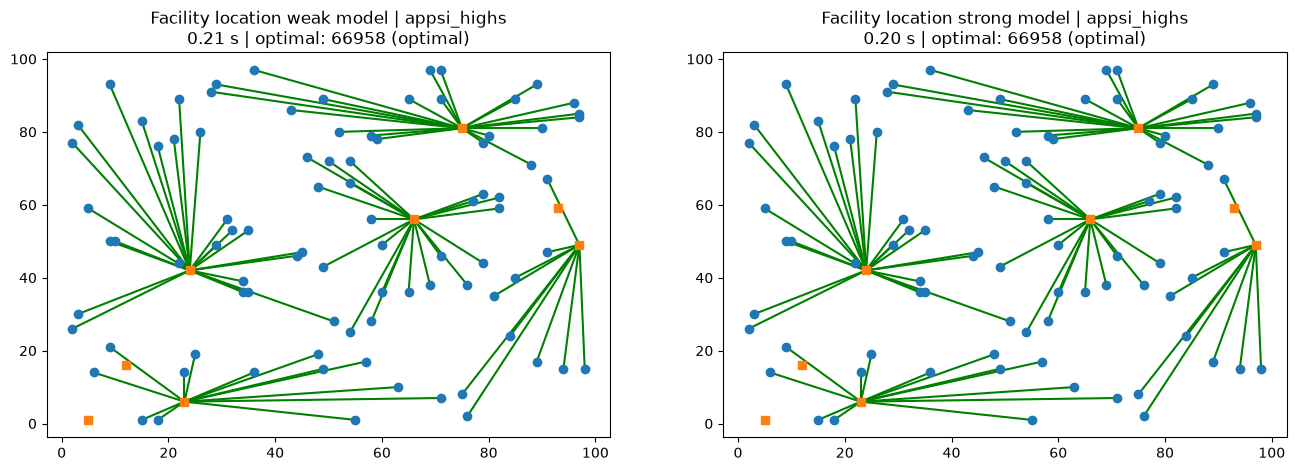

In [14]:
installation, service, xC, yC, xF, yF = GenerateFacilityLocationInstance(8, 88)
weak = FacilityLocationWeak(installation, service)
strong = FacilityLocationStrong(installation, service)

solver_names = ListAvailableSolvers()
if not solver_names:
    raise RuntimeError("No selected solver is available; install highspy.")
_, axs = plt.subplots(len(solver_names), 2, figsize=(16, 5 * len(solver_names)), squeeze=False)
plt.subplots_adjust(hspace=0.5)

for i, solver_name in enumerate(solver_names):
    solver = MakeSolver(solver_name)
    ShowFacilityLocation(xC, yC, xF, yF, *Solve(solver, weak), ax=axs[i, 0])
    ShowFacilityLocation(xC, yC, xF, yF, *Solve(solver, strong), ax=axs[i, 1])

We now compare the weak and strong formulations on larger instances. The tables record termination, the incumbent, its lower bound and the relative gap. Points that reach the time limit measure a truncated run, not the time needed to prove optimality. The elapsed times include the Pyomo solver call and vary with the machine and solver version.

Each record identifies the solver, formulation, experimental setting, random seed and time limit. The displayed tables include the setting so that the default and modified runs remain distinguishable when collected together.

The timings displayed here are new HiGHS runs. Historical CBC timings from earlier versions of this example used a different solver and environment and are not part of this comparison.

In [15]:
benchmark_records = []


def SolveInstances(dimensions, solvers, seed, modify=lambda s: s, *, setting="default"):
    np.random.seed(seed)
    builders = {"weak": FacilityLocationWeak, "strong": FacilityLocationStrong}
    timings = pd.DataFrame(index=pd.MultiIndex.from_tuples(dimensions, names=["facilities", "customers"]),
                           columns=[f"{s}_{m}" for s, m in it.product(solvers, builders)],
                           dtype=float)
    records = []
    for n, count in tqdm(dimensions):
        installation, service, *_ = GenerateFacilityLocationInstance(n, count)
        for solver_name, option in it.product(solvers, builders):
            # Fresh model and solver for each comparison.
            model = builders[option](installation, service)
            record = SolveRecord(modify(MakeSolver(solver_name)), model)
            record.update(facilities=n, customers=count, formulation=option,
                          setting=setting, seed=seed, time_limit_seconds=MAX_SOLVE_SECONDS)
            records.append(record)
            timings.at[(n, count), f"{solver_name}_{option}"] = record["seconds"]
    benchmark_records.extend(records)
    display(pd.DataFrame(records).drop(columns=["optimal", "has_solution", "seed", "time_limit_seconds"]).round(4))
    return timings

We solve instances with 10 to 50 facilities and 100 to 500 customers, with a ten-second limit per solve. First we compare the selected solvers with their default presolve and cut settings. The next two cells repeat the comparison with cuts disabled where supported, and with presolve disabled.

  0%|          | 0/9 [00:00<?, ?it/s]

containing a solution


containing a solution


containing a solution


,solver,seconds,termination,incumbent,lower_bound,relative_gap,facilities,customers,formulation,setting
0,appsi_highs,0.6121,optimal,111015.0,111015.0,0.0000,10,100,weak,default
1,appsi_highs,0.2382,optimal,111015.0,111015.0,0.0000,10,100,strong,default
2,appsi_highs,1.7258,optimal,62214.0,62214.0,0.0000,15,150,weak,default
3,appsi_highs,0.6628,optimal,62214.0,62214.0,0.0000,15,150,strong,default
4,appsi_highs,3.5795,optimal,58652.0,58652.0,0.0000,20,200,weak,default
5,appsi_highs,1.0252,optimal,58652.0,58652.0,0.0000,20,200,strong,default
6,appsi_highs,1.8263,optimal,59932.0,59932.0,0.0000,25,250,weak,default
7,appsi_highs,1.5145,optimal,59932.0,59932.0,0.0000,25,250,strong,default
8,appsi_highs,8.1102,optimal,73983.0,73983.0,0.0000,30,300,weak,default
9,appsi_highs,2.5135,optimal,73983.0,73983.0,0.0000,30,300,strong,default


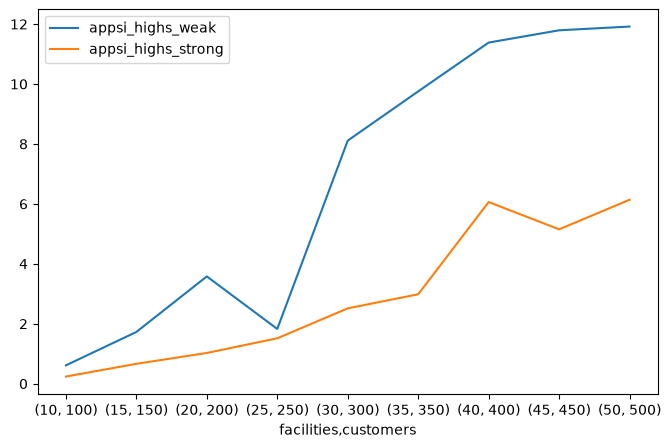

In [16]:
solvers = solver_names
dimensions = [(n, 10 * n) for n in range(10, 51, 5)]

SolveInstances(dimensions, solvers, 2023).plot(figsize=(8, 5))
plt.show()

In [17]:
cut_solvers = [name for name in solvers if "highs" not in name]
if cut_solvers:
    SolveInstances(dimensions, cut_solvers, 2023, SwitchCutsOff, setting="cuts disabled").plot(figsize=(8, 5))
    plt.show()
else:
    print("Cuts-off comparison omitted: the selected HiGHS interface has no cuts-off setting here.")

Cuts-off comparison omitted: the selected HiGHS interface has no cuts-off setting here.


  0%|          | 0/9 [00:00<?, ?it/s]

containing a solution


containing a solution


,solver,seconds,termination,incumbent,lower_bound,relative_gap,facilities,customers,formulation,setting
0,appsi_highs,0.3310,optimal,111015.0,111015.0,0.0000,10,100,weak,presolve disabled
1,appsi_highs,0.2058,optimal,111015.0,111015.0,0.0000,10,100,strong,presolve disabled
2,appsi_highs,0.8279,optimal,62214.0,62214.0,0.0000,15,150,weak,presolve disabled
3,appsi_highs,0.5266,optimal,62214.0,62214.0,0.0000,15,150,strong,presolve disabled
4,appsi_highs,3.4474,optimal,58652.0,58652.0,0.0000,20,200,weak,presolve disabled
5,appsi_highs,0.9266,optimal,58652.0,58652.0,0.0000,20,200,strong,presolve disabled
6,appsi_highs,1.9658,optimal,59932.0,59932.0,0.0000,25,250,weak,presolve disabled
7,appsi_highs,1.3683,optimal,59932.0,59932.0,0.0000,25,250,strong,presolve disabled
8,appsi_highs,8.5574,optimal,73983.0,73983.0,0.0000,30,300,weak,presolve disabled
9,appsi_highs,1.7504,optimal,73983.0,73983.0,0.0000,30,300,strong,presolve disabled


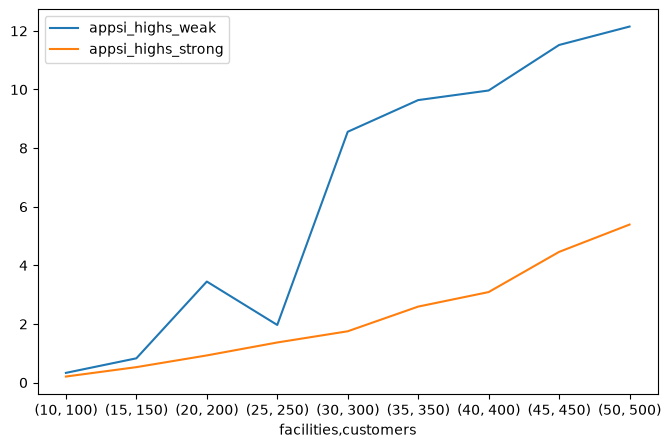

In [18]:
SolveInstances(dimensions, solvers, 2023, SwitchPresolveOff, setting="presolve disabled").plot(figsize=(8, 5))
plt.show()